In [68]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "flight_delay_processed.parquet":
            print(os.path.join(root, file))

In [7]:
from google.colab import files

uploaded = files.upload()

Saving flight_delay_processed.parquet to flight_delay_processed.parquet


In [8]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'flight_delay_processed.parquet', 'sample_data']


In [9]:
import pandas as pd

df = pd.read_parquet("/content/flight_delay_processed.parquet")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [10]:
print("Shape:", df.shape)

Shape: (5713837, 16)


In [11]:
print(df.columns.tolist())

['MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'DISTANCE', 'SCHEDULED_ARRIVAL', 'is_delayed', 'DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'IS_WEEKEND', 'ROUTE']


In [12]:
print(df.dtypes)

MONTH                   int64
DAY                     int64
DAY_OF_WEEK             int64
AIRLINE                object
ORIGIN_AIRPORT         object
DESTINATION_AIRPORT    object
SCHEDULED_DEPARTURE     int64
DISTANCE                int64
SCHEDULED_ARRIVAL       int64
is_delayed               int8
DEP_HOUR                int64
DEP_MINUTE              int64
ARR_HOUR                int64
ARR_MINUTE              int64
IS_WEEKEND               int8
ROUTE                  object
dtype: object


In [13]:
X = df.drop(columns=["is_delayed"])
y = df["is_delayed"]

In [14]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5713837, 15)
y shape: (5713837,)


In [15]:
print("X columns:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

X columns:
['MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'DISTANCE', 'SCHEDULED_ARRIVAL', 'DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'IS_WEEKEND', 'ROUTE']

Target:
is_delayed


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [17]:
print("Training delayed proportion:", y_train.mean())
print("Testing delayed proportion:", y_test.mean())

Training delayed proportion: 0.17912527682255508
Testing delayed proportion: 0.17912559679655013


In [18]:
NUMERIC_FEATURES = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "DISTANCE",
    "DEP_HOUR",
    "DEP_MINUTE",
    "ARR_HOUR",
    "ARR_MINUTE",
    "IS_WEEKEND"
]

CATEGORICAL_FEATURES = [
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "ROUTE"
]

In [19]:
print("Numerical features:")
print(NUMERIC_FEATURES)

print("\nCategorical features:")
print(CATEGORICAL_FEATURES)

Numerical features:
['MONTH', 'DAY', 'DAY_OF_WEEK', 'DISTANCE', 'DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'IS_WEEKEND']

Categorical features:
['AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ROUTE']


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [21]:
from sklearn.preprocessing import OneHotEncoder

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [22]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, NUMERIC_FEATURES),
    ("categorical", categorical_preprocessor, CATEGORICAL_FEATURES)
])

In [23]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        n_jobs=-1
    ))
])

In [24]:
print("Training Logistic Regression...")

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Training Logistic Regression...
Logistic Regression training completed!


In [25]:
logistic_predictions = logistic_model.predict(X_test)

print("Predictions generated!")
print(logistic_predictions[:20])

Predictions generated!
[0 1 0 0 1 1 1 1 1 1 0 1 1 0 0 0 1 1 0 0]


In [26]:
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Probabilities generated!")
print(logistic_probabilities[:20])

Probabilities generated!
[0.25030256 0.53110433 0.48247078 0.31216719 0.53288649 0.65839012
 0.64662595 0.65919568 0.63669632 0.53499637 0.43319123 0.70408335
 0.58728014 0.31777939 0.36214605 0.29017173 0.55926646 0.52825029
 0.14768417 0.43753876]


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    zero_division=0
)
logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    zero_division=0
)
logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    zero_division=0
)
logistic_roc_auc = roc_auc_score(
    y_test,
    logistic_probabilities
)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1-score :", logistic_f1)
print("ROC-AUC  :", logistic_roc_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.6030532881564762
Precision: 0.25371672362377834
Recall   : 0.6263635875114192
F1-score : 0.361146398140976
ROC-AUC  : 0.6520675409683586


In [28]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [29]:
print("Training Random Forest...")

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Training Random Forest...


KeyboardInterrupt: 

In [30]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("Logistic model:", type(logistic_model))

X_train: (4571069, 15)
X_test : (1142768, 15)
y_train: (4571069,)
y_test : (1142768,)
Logistic model: <class 'sklearn.pipeline.Pipeline'>


In [31]:
import psutil

memory = psutil.virtual_memory()

print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")

Total RAM: 12.67 GB
Available RAM: 7.7 GB


In [32]:
from sklearn.model_selection import train_test_split

X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=500_000,
    stratify=y_train,
    random_state=42
)

print("Sample X:", X_train_sample.shape)
print("Sample y:", y_train_sample.shape)

Sample X: (500000, 15)
Sample y: (500000,)


In [33]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=50,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [34]:
print("Training Random Forest on 500,000 rows...")

random_forest_model.fit(
    X_train_sample,
    y_train_sample
)

print("Random Forest training completed!")

Training Random Forest on 500,000 rows...
Random Forest training completed!


In [35]:
random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions generated!")
print(random_forest_predictions[:20])

Predictions generated!
[0 1 0 0 1 1 1 1 1 1 0 1 1 0 0 0 1 1 0 0]


In [36]:
random_forest_probabilities = (
    random_forest_model.predict_proba(X_test)[:, 1]
)

print("Probabilities generated!")
print(random_forest_probabilities[:20])

Probabilities generated!
[0.46386169 0.50603851 0.4778998  0.46255127 0.52036731 0.53533426
 0.54301965 0.52785569 0.520438   0.53575476 0.49039811 0.52735596
 0.53335088 0.49306939 0.47388971 0.4489574  0.51651584 0.50512004
 0.47508623 0.47820754]


In [37]:
random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)

random_forest_precision = precision_score(
    y_test,
    random_forest_predictions,
    zero_division=0
)

random_forest_recall = recall_score(
    y_test,
    random_forest_predictions,
    zero_division=0
)

random_forest_f1 = f1_score(
    y_test,
    random_forest_predictions,
    zero_division=0
)

random_forest_roc_auc = roc_auc_score(
    y_test,
    random_forest_probabilities
)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", random_forest_accuracy)
print("Precision:", random_forest_precision)
print("Recall   :", random_forest_recall)
print("F1-score :", random_forest_f1)
print("ROC-AUC  :", random_forest_roc_auc)

Random Forest Results
---------------------
Accuracy : 0.6085110888649314
Precision: 0.25235924145081107
Recall   : 0.6040723208222806
F1-score : 0.3559962976131697
ROC-AUC  : 0.6449551918370103


In [38]:
X_train_sample.shape

(500000, 15)

In [39]:
X_train_sample_transformed = preprocessor.fit_transform(X_train_sample)

print("Transformed shape:", X_train_sample_transformed.shape)
print("Type:", type(X_train_sample_transformed))

Transformed shape: (500000, 9479)
Type: <class 'scipy.sparse._csr.csr_matrix'>


In [40]:
print("Transformed shape:", X_train_sample_transformed.shape)
print("Type:", type(X_train_sample_transformed))

Transformed shape: (500000, 9479)
Type: <class 'scipy.sparse._csr.csr_matrix'>


In [41]:
from sklearn.preprocessing import OrdinalEncoder

hgb_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        NUMERIC_FEATURES
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "ordinal",
                OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1
                )
            )
        ]),
        CATEGORICAL_FEATURES
    )
])

In [42]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_model = Pipeline([
    ("preprocessor", hgb_preprocessor),
    ("model", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.10,
        max_leaf_nodes=31,
        random_state=42
    ))
])

In [43]:
print("Training HistGradientBoosting...")

hgb_model.fit(
    X_train_sample,
    y_train_sample
)

print("HistGradientBoosting training completed!")

Training HistGradientBoosting...
HistGradientBoosting training completed!


In [44]:
hgb_predictions = hgb_model.predict(X_test)

print("Predictions generated!")
print(hgb_predictions[:20])

Predictions generated!
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [45]:
hgb_probabilities = hgb_model.predict_proba(X_test)[:, 1]

print("Probabilities generated!")
print(hgb_probabilities[:20])

Probabilities generated!
[0.06576519 0.08661845 0.27663745 0.15696757 0.22153836 0.20920988
 0.16299219 0.20526915 0.3770533  0.41110086 0.10358681 0.18857529
 0.35976674 0.12003332 0.14593395 0.10191697 0.11489319 0.14134428
 0.13948475 0.10353451]


In [46]:
hgb_accuracy = accuracy_score(
    y_test,
    hgb_predictions
)

hgb_precision = precision_score(
    y_test,
    hgb_predictions,
    zero_division=0
)

hgb_recall = recall_score(
    y_test,
    hgb_predictions,
    zero_division=0
)

hgb_f1 = f1_score(
    y_test,
    hgb_predictions,
    zero_division=0
)

hgb_roc_auc = roc_auc_score(
    y_test,
    hgb_probabilities
)

print("HistGradientBoosting Results")
print("----------------------------")
print("Accuracy :", hgb_accuracy)
print("Precision:", hgb_precision)
print("Recall   :", hgb_recall)
print("F1-score :", hgb_f1)
print("ROC-AUC  :", hgb_roc_auc)

HistGradientBoosting Results
----------------------------
Accuracy : 0.8233158436358036
Precision: 0.6548279689234184
Recall   : 0.02882280812314667
F1-score : 0.05521526936160854
ROC-AUC  : 0.7047831296220477


In [47]:
results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_accuracy,
        "Precision": logistic_precision,
        "Recall": logistic_recall,
        "F1": logistic_f1,
        "ROC_AUC": logistic_roc_auc
    },
    {
        "Model": "Random Forest",
        "Accuracy": random_forest_accuracy,
        "Precision": random_forest_precision,
        "Recall": random_forest_recall,
        "F1": random_forest_f1,
        "ROC_AUC": random_forest_roc_auc
    },
    {
        "Model": "HistGradientBoosting",
        "Accuracy": hgb_accuracy,
        "Precision": hgb_precision,
        "Recall": hgb_recall,
        "F1": hgb_f1,
        "ROC_AUC": hgb_roc_auc
    }
]

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.603053,0.253717,0.626364,0.361146,0.652068
1,Random Forest,0.608511,0.252359,0.604072,0.355996,0.644955
2,HistGradientBoosting,0.823316,0.654828,0.028823,0.055215,0.704783


In [48]:
X_train_common, _, y_train_common, _ = train_test_split(
    X_train,
    y_train,
    train_size=500_000,
    stratify=y_train,
    random_state=42
)

print("Common training set:", X_train_common.shape)
print("Common target set:", y_train_common.shape)

Common training set: (500000, 15)
Common target set: (500000,)


In [49]:
print("Common training distribution:")
print(y_train_common.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))

Common training distribution:
is_delayed
0    0.820874
1    0.179126
Name: proportion, dtype: float64

Test distribution:
is_delayed
0    0.820874
1    0.179126
Name: proportion, dtype: float64


In [50]:
print("Retraining Logistic Regression...")

logistic_model_common = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        n_jobs=-1
    ))
])

logistic_model_common.fit(
    X_train_common,
    y_train_common
)

print("Logistic Regression completed!")

Retraining Logistic Regression...
Logistic Regression completed!


In [51]:
logistic_common_predictions = logistic_model_common.predict(X_test)

logistic_common_probabilities = (
    logistic_model_common.predict_proba(X_test)[:, 1]
)

In [52]:
logistic_common_accuracy = accuracy_score(
    y_test,
    logistic_common_predictions
)

logistic_common_precision = precision_score(
    y_test,
    logistic_common_predictions,
    zero_division=0
)

logistic_common_recall = recall_score(
    y_test,
    logistic_common_predictions,
    zero_division=0
)

logistic_common_f1 = f1_score(
    y_test,
    logistic_common_predictions,
    zero_division=0
)

logistic_common_roc_auc = roc_auc_score(
    y_test,
    logistic_common_probabilities
)

print("Logistic Regression — Common Sample")
print("------------------------------------")
print("Accuracy :", logistic_common_accuracy)
print("Precision:", logistic_common_precision)
print("Recall   :", logistic_common_recall)
print("F1-score :", logistic_common_f1)
print("ROC-AUC  :", logistic_common_roc_auc)

Logistic Regression — Common Sample
------------------------------------
Accuracy : 0.6016356775828514
Precision: 0.2492026787591219
Recall   : 0.6080782026292263
F1-score : 0.353524078933915
ROC-AUC  : 0.6403816119493433


In [53]:
print("Training Random Forest on common sample...")

random_forest_common = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=50,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_common.fit(
    X_train_common,
    y_train_common
)

print("Random Forest completed!")

Training Random Forest on common sample...
Random Forest completed!


In [54]:
random_forest_common_predictions = (
    random_forest_common.predict(X_test)
)

random_forest_common_probabilities = (
    random_forest_common.predict_proba(X_test)[:, 1]
)

print("Random Forest predictions completed!")

Random Forest predictions completed!


In [55]:
random_forest_common_accuracy = accuracy_score(
    y_test,
    random_forest_common_predictions
)

random_forest_common_precision = precision_score(
    y_test,
    random_forest_common_predictions,
    zero_division=0
)

random_forest_common_recall = recall_score(
    y_test,
    random_forest_common_predictions,
    zero_division=0
)

random_forest_common_f1 = f1_score(
    y_test,
    random_forest_common_predictions,
    zero_division=0
)

random_forest_common_roc_auc = roc_auc_score(
    y_test,
    random_forest_common_probabilities
)

print("Random Forest — Common Sample")
print("------------------------------")
print("Accuracy :", random_forest_common_accuracy)
print("Precision:", random_forest_common_precision)
print("Recall   :", random_forest_common_recall)
print("F1-score :", random_forest_common_f1)
print("ROC-AUC  :", random_forest_common_roc_auc)

Random Forest — Common Sample
------------------------------
Accuracy : 0.6085110888649314
Precision: 0.25235924145081107
Recall   : 0.6040723208222806
F1-score : 0.3559962976131697
ROC-AUC  : 0.6449551919125227


In [56]:
print("Training HistGradientBoosting on common sample...")

hgb_model_common = Pipeline([
    ("preprocessor", hgb_preprocessor),
    ("model", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.10,
        max_leaf_nodes=31,
        random_state=42
    ))
])

hgb_model_common.fit(
    X_train_common,
    y_train_common
)

print("HistGradientBoosting completed!")

Training HistGradientBoosting on common sample...
HistGradientBoosting completed!


In [57]:
hgb_common_predictions = hgb_model_common.predict(X_test)

hgb_common_probabilities = (
    hgb_model_common.predict_proba(X_test)[:, 1]
)

print("HistGradientBoosting predictions completed!")

HistGradientBoosting predictions completed!


In [58]:
hgb_common_accuracy = accuracy_score(
    y_test,
    hgb_common_predictions
)

hgb_common_precision = precision_score(
    y_test,
    hgb_common_predictions,
    zero_division=0
)

hgb_common_recall = recall_score(
    y_test,
    hgb_common_predictions,
    zero_division=0
)

hgb_common_f1 = f1_score(
    y_test,
    hgb_common_predictions,
    zero_division=0
)

hgb_common_roc_auc = roc_auc_score(
    y_test,
    hgb_common_probabilities
)

print("HistGradientBoosting — Common Sample")
print("--------------------------------------")
print("Accuracy :", hgb_common_accuracy)
print("Precision:", hgb_common_precision)
print("Recall   :", hgb_common_recall)
print("F1-score :", hgb_common_f1)
print("ROC-AUC  :", hgb_common_roc_auc)

HistGradientBoosting — Common Sample
--------------------------------------
Accuracy : 0.8233158436358036
Precision: 0.6548279689234184
Recall   : 0.02882280812314667
F1-score : 0.05521526936160854
ROC-AUC  : 0.7047831296220477


In [60]:
print("Logistic Regression — Common Sample")
print("------------------------------------")
print("Accuracy :", logistic_common_accuracy)
print("Precision:", logistic_common_precision)
print("Recall   :", logistic_common_recall)
print("F1-score :", logistic_common_f1)
print("ROC-AUC  :", logistic_common_roc_auc)

Logistic Regression — Common Sample
------------------------------------
Accuracy : 0.6016356775828514
Precision: 0.2492026787591219
Recall   : 0.6080782026292263
F1-score : 0.353524078933915
ROC-AUC  : 0.6403816119493433


In [61]:
final_results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_common_accuracy,
        "Precision": logistic_common_precision,
        "Recall": logistic_common_recall,
        "F1": logistic_common_f1,
        "ROC_AUC": logistic_common_roc_auc
    },
    {
        "Model": "Random Forest",
        "Accuracy": random_forest_common_accuracy,
        "Precision": random_forest_common_precision,
        "Recall": random_forest_common_recall,
        "F1": random_forest_common_f1,
        "ROC_AUC": random_forest_common_roc_auc
    },
    {
        "Model": "HistGradientBoosting",
        "Accuracy": hgb_common_accuracy,
        "Precision": hgb_common_precision,
        "Recall": hgb_common_recall,
        "F1": hgb_common_f1,
        "ROC_AUC": hgb_common_roc_auc
    }
]

final_results_df = pd.DataFrame(final_results)

final_results_df = final_results_df.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

final_results_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,0.608511,0.252359,0.604072,0.355996,0.644955
1,Logistic Regression,0.601636,0.249203,0.608078,0.353524,0.640382
2,HistGradientBoosting,0.823316,0.654828,0.028823,0.055215,0.704783


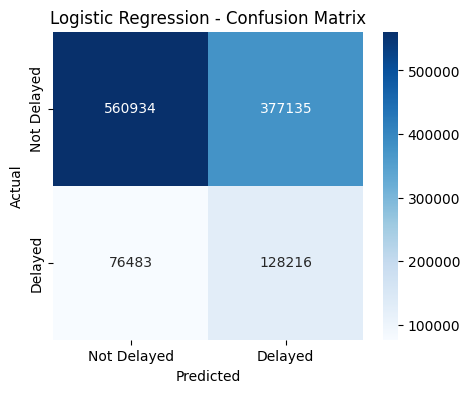

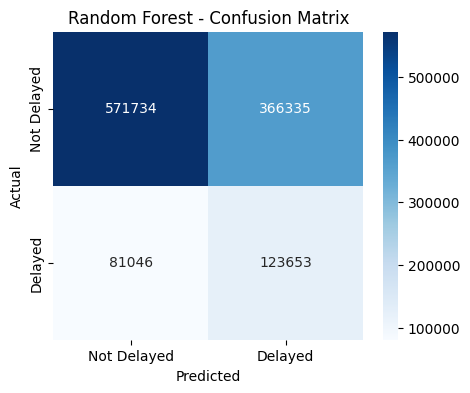

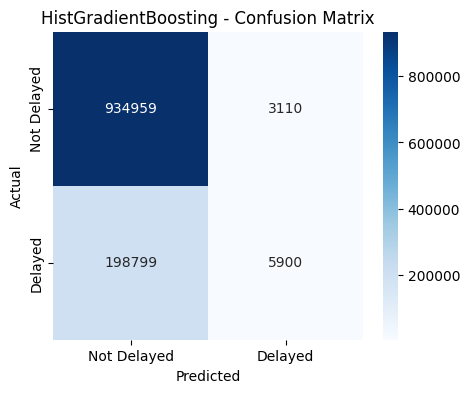

In [62]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

models_predictions = {
    "Logistic Regression": logistic_predictions,
    "Random Forest": random_forest_predictions,
    "HistGradientBoosting": hgb_predictions
}

for name, predictions in models_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Delayed", "Delayed"],
        yticklabels=["Not Delayed", "Delayed"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [63]:
from sklearn.metrics import classification_report

for name, predictions in models_predictions.items():
    print("=" * 60)
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test,
        predictions,
        target_names=["Not Delayed", "Delayed"]
    ))

Logistic Regression
              precision    recall  f1-score   support

 Not Delayed       0.88      0.60      0.71    938069
     Delayed       0.25      0.63      0.36    204699

    accuracy                           0.60   1142768
   macro avg       0.57      0.61      0.54   1142768
weighted avg       0.77      0.60      0.65   1142768

Random Forest
              precision    recall  f1-score   support

 Not Delayed       0.88      0.61      0.72    938069
     Delayed       0.25      0.60      0.36    204699

    accuracy                           0.61   1142768
   macro avg       0.56      0.61      0.54   1142768
weighted avg       0.76      0.61      0.65   1142768

HistGradientBoosting
              precision    recall  f1-score   support

 Not Delayed       0.82      1.00      0.90    938069
     Delayed       0.65      0.03      0.06    204699

    accuracy                           0.82   1142768
   macro avg       0.74      0.51      0.48   1142768
weighted avg       

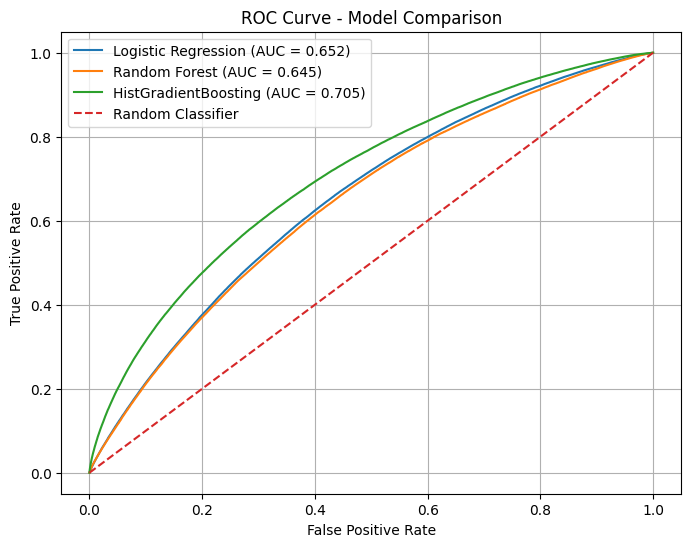

In [64]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC curve for each model
fpr_logistic, tpr_logistic, _ = roc_curve(y_test, logistic_probabilities)
fpr_rf, tpr_rf, _ = roc_curve(y_test, random_forest_probabilities)
fpr_hgb, tpr_hgb, _ = roc_curve(y_test, hgb_probabilities)

# Calculate AUC
auc_logistic = auc(fpr_logistic, tpr_logistic)
auc_rf = auc(fpr_rf, tpr_rf)
auc_hgb = auc(fpr_hgb, tpr_hgb)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {auc_logistic:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    fpr_hgb,
    tpr_hgb,
    label=f"HistGradientBoosting (AUC = {auc_hgb:.3f})"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Model Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [65]:
random_forest_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

hgb_probabilities = hgb_model.predict_proba(X_test)[:, 1]

In [66]:
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "Accuracy": [
        0.6016356776,
        0.6085110889,
        0.8233158436
    ],
    "Precision": [
        0.2492026788,
        0.2523592415,
        0.6548279689
    ],
    "Recall": [
        0.6080782026,
        0.6040723208,
        0.0288228081
    ],
    "F1-Score": [
        0.3535240789,
        0.3559962976,
        0.0552152694
    ],
    "ROC-AUC": [
        0.652,
        0.645,
        0.705
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.601636,0.249203,0.608078,0.353524,0.652
1,Random Forest,0.608511,0.252359,0.604072,0.355996,0.645
2,HistGradientBoosting,0.823316,0.654828,0.028823,0.055215,0.705


In [67]:
comparison_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Comparison table saved successfully!")

Comparison table saved successfully!
